# Лабораторна робота №4
Розпізнавання образів за кількісними та якісними характеристиками (міра Евкліда)

In [1]:
# Підключення бібліотек
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # щоб результати повторювались
print('NumPy', np.__version__)
print('Бібліотеки підключено успішно')

NumPy 2.5.3
Бібліотеки підключено успішно


In [2]:
# ЧАСТИНА 1. Розпізнавання тварин за якісними ознаками
# кожна ознака кодується 1 (є) або 0 (немає)
features_q = ['шерсть', 'пір\'я', 'луска', 'літає', 'у воді',
              'ноги', 'яйця', 'хижак']

# еталонні образи (класи)
etalons_q = {
    'Кіт':      [1, 0, 0, 0, 0, 1, 0, 1],
    'Орел':     [0, 1, 0, 1, 0, 1, 1, 1],
    'Окунь':    [0, 0, 1, 0, 1, 0, 1, 1],
    'Жаба':     [0, 0, 0, 0, 1, 1, 1, 1],
    'Змія':     [0, 0, 1, 0, 0, 0, 1, 1],
    'Кажан':    [1, 0, 0, 1, 0, 1, 0, 1],
    'Пінгвін':  [0, 1, 0, 0, 1, 1, 1, 1],
    'Корова':   [1, 0, 0, 0, 0, 1, 0, 0],
}

names_q = list(etalons_q.keys())
X_q = np.array(list(etalons_q.values()))

print(f"{'Клас':<10}" + ''.join(f'{f:>8}' for f in features_q))
for name, vec in etalons_q.items():
    print(f'{name:<10}' + ''.join(f'{v:>8}' for v in vec))

Клас        шерсть   пір'я   луска   літає  у воді    ноги    яйця   хижак
Кіт              1       0       0       0       0       1       0       1
Орел             0       1       0       1       0       1       1       1
Окунь            0       0       1       0       1       0       1       1
Жаба             0       0       0       0       1       1       1       1
Змія             0       0       1       0       0       0       1       1
Кажан            1       0       0       1       0       1       0       1
Пінгвін          0       1       0       0       1       1       1       1
Корова           1       0       0       0       0       1       0       0


In [3]:
# відстань L_i = сума (s_k - x_k)^2  (квадрат евклідової відстані)
def distance_sq(s, x):
    s, x = np.asarray(s, float), np.asarray(x, float)
    return np.sum((s - x) ** 2)

def recognize_q(s, max_dist=2):
    """Повертає (клас, відстані). max_dist - поріг, після якого
    об'єкт вважається невідомим."""
    dists = np.array([distance_sq(s, x) for x in X_q])
    best = dists.min()
    winners = [names_q[i] for i in np.where(dists == best)[0]]
    if best > max_dist:
        result = 'невідомий образ'
    elif len(winners) > 1:
        result = 'неоднозначно: ' + ' / '.join(winners)
    else:
        result = winners[0]
    return result, dists

def show_q(title, s):
    result, dists = recognize_q(s)
    print(f'{title}: S = {s}')
    for name, d in sorted(zip(names_q, dists), key=lambda t: t[1]):
        print(f'   L({name:<8}) = {d:.0f}')
    print(f'   => Результат: {result}\n')

In [4]:
# Контрольні приклади (якісні ознаки)
show_q('Об\'єкт 1 (рись)',      [1, 0, 0, 0, 0, 1, 0, 1])
show_q('Об\'єкт 2 (голуб)',     [0, 1, 0, 1, 0, 1, 1, 0])
show_q('Об\'єкт 3 (кінь)',      [1, 0, 0, 0, 1, 1, 0, 0])

Об'єкт 1 (рись): S = [1, 0, 0, 0, 0, 1, 0, 1]
   L(Кіт     ) = 0
   L(Кажан   ) = 1
   L(Корова  ) = 1
   L(Жаба    ) = 3
   L(Орел    ) = 4
   L(Змія    ) = 4
   L(Пінгвін ) = 4
   L(Окунь   ) = 5
   => Результат: Кіт

Об'єкт 2 (голуб): S = [0, 1, 0, 1, 0, 1, 1, 0]
   L(Орел    ) = 1
   L(Пінгвін ) = 3
   L(Жаба    ) = 4
   L(Кажан   ) = 4
   L(Корова  ) = 4
   L(Кіт     ) = 5
   L(Змія    ) = 5
   L(Окунь   ) = 6
   => Результат: Орел

Об'єкт 3 (кінь): S = [1, 0, 0, 0, 1, 1, 0, 0]
   L(Корова  ) = 1
   L(Кіт     ) = 2
   L(Жаба    ) = 3
   L(Кажан   ) = 3
   L(Пінгвін ) = 4
   L(Окунь   ) = 5
   L(Орел    ) = 6
   L(Змія    ) = 6
   => Результат: Корова



In [5]:
# Ситуації, в яких алгоритм не дає однозначної відповіді
show_q('Об\'єкт 4 (качка)',     [0, 1, 0, 1, 1, 1, 1, 0])
show_q('Об\'єкт 5 (крокодил)',  [0, 0, 1, 0, 1, 1, 1, 1])
show_q('Об\'єкт 6 (метелик)',   [0, 0, 1, 1, 0, 1, 1, 0])

Об'єкт 4 (качка): S = [0, 1, 0, 1, 1, 1, 1, 0]
   L(Орел    ) = 2
   L(Пінгвін ) = 2
   L(Жаба    ) = 3
   L(Окунь   ) = 5
   L(Кажан   ) = 5
   L(Корова  ) = 5
   L(Кіт     ) = 6
   L(Змія    ) = 6
   => Результат: неоднозначно: Орел / Пінгвін

Об'єкт 5 (крокодил): S = [0, 0, 1, 0, 1, 1, 1, 1]
   L(Окунь   ) = 1
   L(Жаба    ) = 1
   L(Змія    ) = 2
   L(Пінгвін ) = 2
   L(Кіт     ) = 4
   L(Орел    ) = 4
   L(Кажан   ) = 5
   L(Корова  ) = 5
   => Результат: неоднозначно: Окунь / Жаба

Об'єкт 6 (метелик): S = [0, 0, 1, 1, 0, 1, 1, 0]
   L(Орел    ) = 3
   L(Змія    ) = 3
   L(Окунь   ) = 4
   L(Жаба    ) = 4
   L(Кажан   ) = 4
   L(Корова  ) = 4
   L(Кіт     ) = 5
   L(Пінгвін ) = 5
   => Результат: невідомий образ



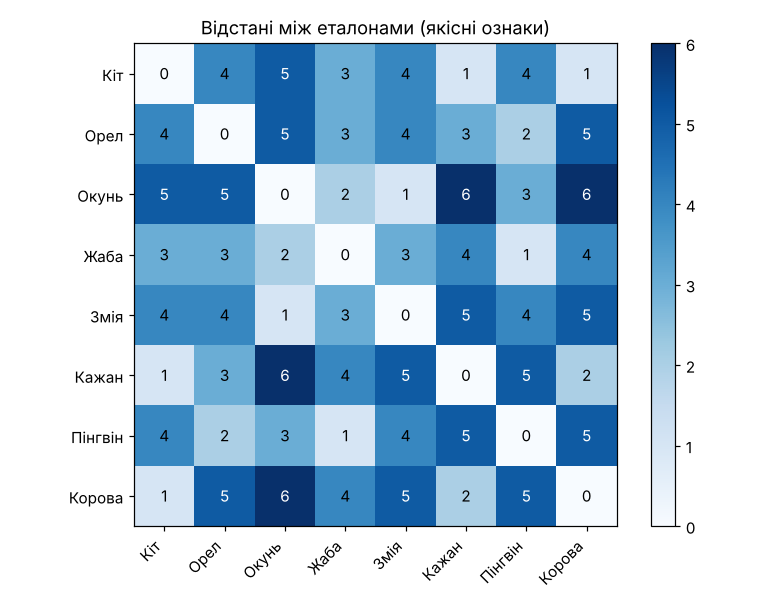

In [6]:
# матриця відстаней між самими еталонами
D_q = np.array([[distance_sq(a, b) for b in X_q] for a in X_q])
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(D_q, cmap='Blues')
ax.set_xticks(range(len(names_q)), names_q, rotation=45, ha='right')
ax.set_yticks(range(len(names_q)), names_q)
for i in range(len(names_q)):
    for j in range(len(names_q)):
        ax.text(j, i, int(D_q[i, j]), ha='center', va='center',
                color='white' if D_q[i, j] > 4 else 'black')
ax.set_title('Відстані між еталонами (якісні ознаки)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [7]:
# ЧАСТИНА 2. Розпізнавання фруктів за кількісними ознаками
features_k = ['маса, г', 'діаметр, см', 'цукор, °Brix', 'pH']

# середні значення та розкид ознак для кожного класу
classes_k = {
    'Яблуко':   ([180, 7.5, 13.0, 3.5], [25, 0.5, 1.2, 0.20]),
    'Апельсин': ([200, 7.8, 11.0, 3.7], [30, 0.6, 1.0, 0.20]),
    'Лимон':    ([110, 6.0,  2.5, 2.3], [15, 0.4, 0.6, 0.15]),
    'Слива':    ([ 40, 4.2, 14.0, 3.3], [ 8, 0.4, 1.5, 0.20]),
    'Мандарин': ([ 90, 5.8, 12.0, 3.8], [15, 0.4, 1.2, 0.20]),
}
names_k = list(classes_k.keys())

def make_samples(n):
    X, y = [], []
    for c, (mean, std) in enumerate(classes_k.values()):
        X.append(np.random.normal(mean, std, size=(n, 4)))
        y += [c] * n
    return np.vstack(X), np.array(y)

X_train, y_train = make_samples(15)   # навчальна вибірка
X_test,  y_test  = make_samples(20)   # тестова вибірка
print('Навчальна вибірка:', X_train.shape, ' тестова:', X_test.shape)
print('\nПерші 5 об\'єктів навчальної вибірки:')
for x, c in zip(X_train[:5], y_train[:5]):
    print('  ', np.round(x, 2), '->', names_k[c])

Навчальна вибірка: (75, 4)  тестова: (100, 4)

Перші 5 об'єктів навчальної вибірки:
   [192.42   7.43  13.78   3.8 ] -> Яблуко
   [174.15   7.38  14.9    3.65] -> Яблуко
   [168.26   7.77  12.44   3.41] -> Яблуко
   [186.05   6.54  10.93   3.39] -> Яблуко
   [154.68   7.66  11.91   3.22] -> Яблуко


In [8]:
# еталон класу = середнє значення ознак його навчальних об'єктів
etalons_k = np.array([X_train[y_train == c].mean(axis=0)
                      for c in range(len(names_k))])
print(f"{'Еталон':<10}" + ''.join(f'{f:>14}' for f in features_k))
for name, e in zip(names_k, etalons_k):
    print(f'{name:<10}' + ''.join(f'{v:>14.2f}' for v in e))

# нормалізація min-max за навчальною вибіркою
x_min, x_max = X_train.min(axis=0), X_train.max(axis=0)
def normalize(X):
    return (np.asarray(X, float) - x_min) / (x_max - x_min)

Еталон           маса, г   діаметр, см  цукор, °Brix            pH
Яблуко            176.04          7.27         12.84          3.53
Апельсин          194.98          7.93         10.96          3.70
Лимон             111.51          6.17          2.35          2.31
Слива              38.78          4.22         14.21          3.34
Мандарин           95.74          5.74         11.92          3.75


In [9]:
def euclid(a, b):
    return np.sqrt(np.sum((np.asarray(a) - np.asarray(b)) ** 2, axis=-1))

def recognize_k(x, use_norm=True, max_dist=0.6):
    """Клас з найменшою евклідовою відстанню до еталона."""
    if use_norm:
        d = euclid(normalize(x), normalize(etalons_k))
    else:
        d = euclid(x, etalons_k)
    c = int(np.argmin(d))
    if use_norm and d[c] > max_dist:
        return 'невідомий образ', d
    return names_k[c], d

def accuracy(use_norm):
    pred = [recognize_k(x, use_norm)[0] for x in X_test]
    true = [names_k[c] for c in y_test]
    return np.mean([p == t for p, t in zip(pred, true)]), pred

acc_raw, pred_raw = accuracy(False)
acc_norm, pred_norm = accuracy(True)
print(f'Точність без нормалізації: {acc_raw * 100:.1f}%')
print(f'Точність з нормалізацією:  {acc_norm * 100:.1f}%')

Точність без нормалізації: 73.0%
Точність з нормалізацією:  96.0%


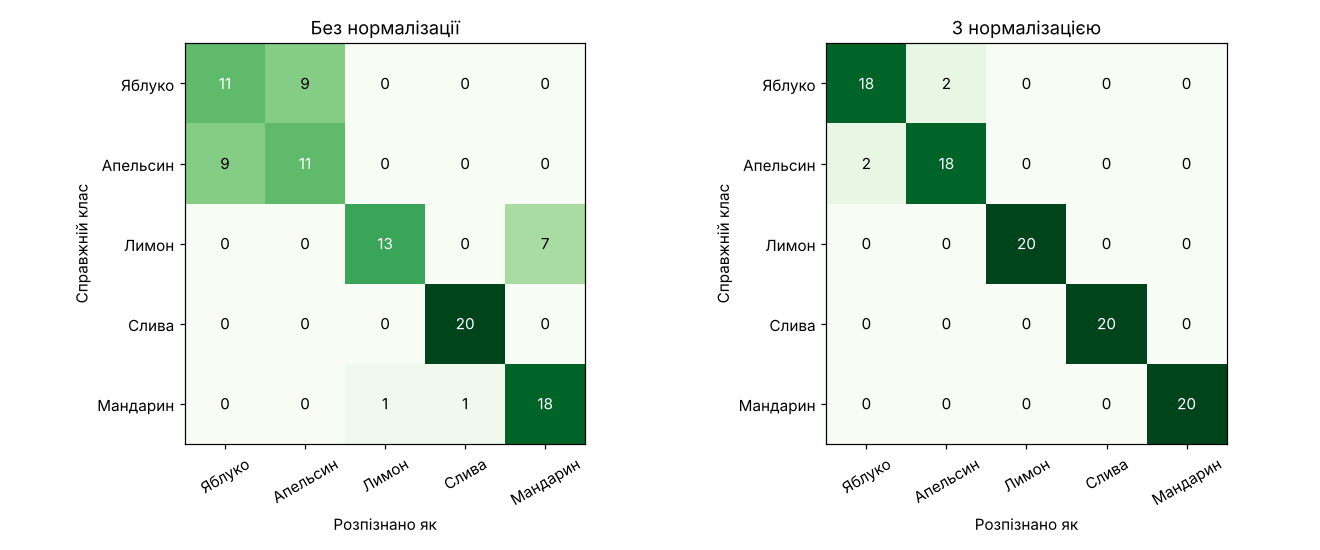

In [10]:
# матриці помилок
def confusion(pred):
    M = np.zeros((len(names_k), len(names_k)), int)
    for p, t in zip(pred, y_test):
        if p in names_k:
            M[t, names_k.index(p)] += 1
    return M

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in [(axes[0], pred_raw, 'Без нормалізації'),
                        (axes[1], pred_norm, 'З нормалізацією')]:
    M = confusion(pred)
    ax.imshow(M, cmap='Greens')
    for i in range(len(names_k)):
        for j in range(len(names_k)):
            ax.text(j, i, M[i, j], ha='center', va='center',
                    color='white' if M[i, j] > 10 else 'black')
    ax.set_xticks(range(len(names_k)), names_k, rotation=30)
    ax.set_yticks(range(len(names_k)), names_k)
    ax.set_xlabel('Розпізнано як'); ax.set_ylabel('Справжній клас')
    ax.set_title(title)
plt.tight_layout()
plt.show()

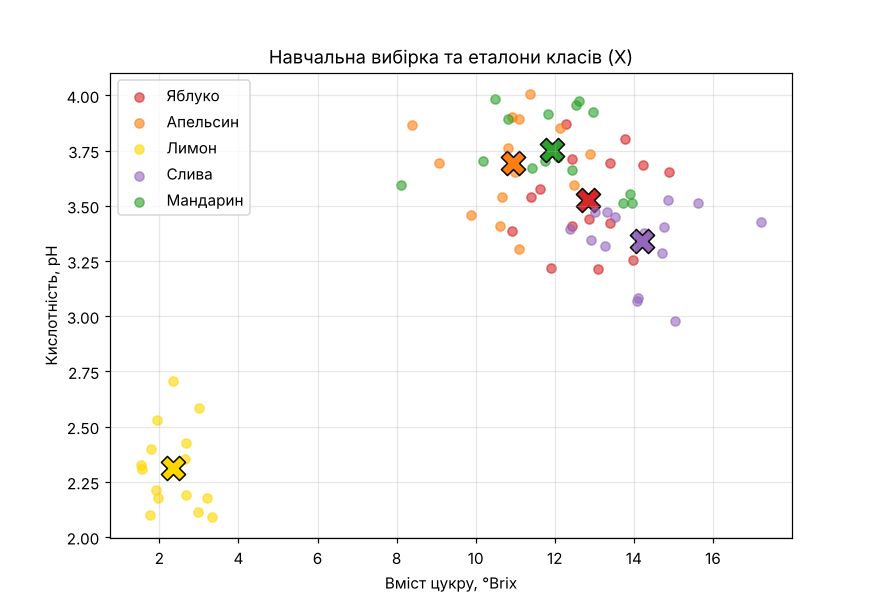

In [11]:
# простір ознак "цукор - pH" з еталонами
colors = ['tab:red', 'tab:orange', 'gold', 'tab:purple', 'tab:green']
plt.figure(figsize=(8, 5.5))
for c, name in enumerate(names_k):
    pts = X_train[y_train == c]
    plt.scatter(pts[:, 2], pts[:, 3], color=colors[c], alpha=0.6, label=name)
    plt.scatter(*etalons_k[c, 2:], color=colors[c], marker='X', s=250,
                edgecolor='black')
plt.xlabel('Вміст цукру, °Brix'); plt.ylabel('Кислотність, pH')
plt.title('Навчальна вибірка та еталони класів (X)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [12]:
# Контрольні приклади (кількісні ознаки)
def show_k(title, x):
    result, d = recognize_k(x)
    print(f'{title}: {x}')
    for name, v in sorted(zip(names_k, d), key=lambda t: t[1]):
        print(f'   d({name:<8}) = {v:.3f}')
    print(f'   => Результат: {result}\n')

show_k('Фрукт 1', [175, 7.4, 13.5, 3.4])
show_k('Фрукт 2', [105, 5.9, 3.0, 2.4])
show_k('Фрукт 3', [45, 4.0, 15.0, 3.2])

Фрукт 1: [175, 7.4, 13.5, 3.4]
   d(Яблуко  ) = 0.081
   d(Апельсин) = 0.261
   d(Мандарин) = 0.530
   d(Слива   ) = 0.874
   d(Лимон   ) = 0.985
   => Результат: Яблуко

Фрукт 2: [105, 5.9, 3.0, 2.4]
   d(Лимон   ) = 0.083
   d(Мандарин) = 0.907
   d(Яблуко  ) = 0.959
   d(Слива   ) = 0.972
   d(Апельсин) = 1.018
   => Результат: Лимон

Фрукт 3: [45, 4.0, 15.0, 3.2]
   d(Слива   ) = 0.101
   d(Мандарин) = 0.524
   d(Яблуко  ) = 0.889
   d(Лимон   ) = 1.055
   d(Апельсин) = 1.071
   => Результат: Слива



In [13]:
# Ситуації, де алгоритм помиляється або не застосовний
show_k('Фрукт 4 (на межі яблуко/апельсин)', [190, 7.6, 12.0, 3.6])
show_k('Фрукт 5 (кавун)', [5000, 25.0, 9.0, 5.5])

# без нормалізації маса "заглушує" інші ознаки
x = [95, 6.0, 2.8, 2.3]   # це лимон, але легкий
print('Легкий лимон без нормалізації:', recognize_k(x, use_norm=False)[0])
print('Легкий лимон з нормалізацією: ', recognize_k(x, use_norm=True)[0])

Фрукт 4 (на межі яблуко/апельсин): [190, 7.6, 12.0, 3.6]
   d(Апельсин) = 0.104
   d(Яблуко  ) = 0.112
   d(Мандарин) = 0.574
   d(Слива   ) = 0.972
   d(Лимон   ) = 1.021
   => Результат: Апельсин

Фрукт 5 (кавун): [5000, 25.0, 9.0, 5.5]
   d(Апельсин) = 24.153
   d(Яблуко  ) = 24.265
   d(Лимон   ) = 24.645
   d(Мандарин) = 24.691
   d(Слива   ) = 25.018
   => Результат: невідомий образ

Легкий лимон без нормалізації: Мандарин
Легкий лимон з нормалізацією:  Лимон


In [14]:
# Введення ознак з клавіатури (інтерфейс користувача)
def user_input():
    print('Режим: 1 - тварина (якісні ознаки), 2 - фрукт (кількісні ознаки)')
    mode = input('Ваш вибір: ').strip()
    if mode == '1':
        s = [int(input(f'  {f} (1 - так, 0 - ні): ')) for f in features_q]
        show_q('Введений об\'єкт', s)
    elif mode == '2':
        x = [float(input(f'  {f}: ').replace(',', '.')) for f in features_k]
        show_k('Введений фрукт', x)
    else:
        print('Невірний режим')

user_input()

Режим: 1 - тварина (якісні ознаки), 2 - фрукт (кількісні ознаки)
Ваш вибір: 2
  маса, г: 120
  діаметр, см: 6,2
  цукор, °Brix: 11.5
  pH: 3.7
Введений фрукт: [120.0, 6.2, 11.5, 3.7]
   d(Мандарин) = 0.149
   d(Яблуко  ) = 0.357
   d(Апельсин) = 0.479
   d(Слива   ) = 0.587
   d(Лимон   ) = 0.930
   => Результат: Мандарин

